# Project 1 Starter Code
---
<div class="alert alert-block alert-success" style="color:black;">
<b>To Begin:</b> Use this <b>Project_1_Starter_Code.ipynb</b> if you choose to develop your project.
<br><br>
<b>When Finished:</b> When you have completed your work, submit either a .ipynb file or a .py file to BrightSpace.
</div>

<div class="alert alert-block alert-danger" style="color:black;">
<b>GPU/CUDA/Memory Warnings/Errors:</b> You may receive some errors referencing that GPUs will not be used, CUDA could not be found, or free system memory allocation errors. These and a few others, are standard errors that can be ignored here as they are environment based.<br><br>
<b>Example messages:</b>
    <ul>
        <li>Could not find cuda drivers on your machine, GPU will not be used.</li>
        <li>Please check linkage and avoid linking the same target more than once.</li>
        <li>E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)</li>
        <li>Allocation of ######## exceeds 10% of free system memory</li>
    </ul>
</div>

<div class="alert alert-block alert-info" style="color:black;">
    The following packages are starter packages for Project 1. You will need to install more to complete this project. You may want to reference previous assignments to determine the packages needed.
</div>

In [1]:
# Potential Packages used for Project 1
import os
import random
import numpy as np
import torch
import pandas as pd
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from transformers import AutoModelForSequenceClassification, Trainer, TrainingArguments
from transformers import Trainer, TrainingArguments

# Can use the packages below for plots and graphs
import matplotlib.pyplot as plt
import seaborn as sns

# You may want to import the imdb dataset from tensorflow.keras.datasets
from datasets import load_dataset

2026-11-08 02:10:22.505018: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/home/ubuntu/.local/lib/python3.13/site-packages/keras/src/export/tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


In [2]:
import sys
!{sys.executable} -m pip install accelerate --no-deps --break-system-packages

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [2]:
# Used for reproducibility and seeding
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


### TODO: Load IMDb Dataset

In [3]:
# Load your IMDb Dataset
MAX_NUMBS = 1000 # Narrowing down to help with building in Codio. Feel free to edit this value as you wish.
SKIP_COMMON = False
# Load the IMDb dataset via Hugging Face
dataset = load_dataset("imdb")

# Inspect the dataset structure
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


### TODO: Analyze the Dataset

Sample Review (Label: Negative):
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really h...

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.
Class Distribution
Negative (0): 512
Positive (1): 488

Text Characteristics (Word Count Statistics)
count    1000.000000
mean      231.553000
std       171.781076
min        31.000000
25%       127.000000
50%       175.000000
75%       271.000000
max      1005.000000
Name: word_count, dtype: float64


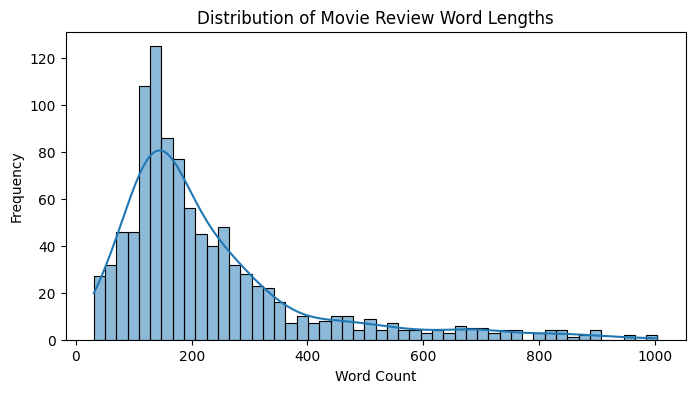

In [23]:
# Inspect and analyze your dataset. 
# HINT: You may want to decode it to use it.

def decode_movie_review(split="train", index=0):
    example = dataset[split][index]
    text = example["text"]
    label_map = {0: "Negative", 1: "Positive"}
    label_str = label_map[example["label"]]
    return text, label_str

# Test the function by displaying the first review
sample_text, sample_label = decode_movie_review(split="train", index=0)
print(f"Sample Review (Label: {sample_label}):\n{sample_text[:300]}...\n")

# Subsample dataset
small_train_dataset = dataset["train"].shuffle(seed=42).select(range(MAX_NUMBS))
small_test_dataset = dataset["test"].shuffle(seed=42).select(range(min(2000, len(dataset["test"]))))
df_train = pd.DataFrame(small_train_dataset)

# Class Distribution
class_counts = df_train["label"].value_counts()
print("Class Distribution")
print(f"Negative (0): {class_counts[0]}")
print(f"Positive (1): {class_counts[1]}")

# Word counts
df_train["word_count"] = df_train["text"].apply(lambda x: len(x.split()))

print("\nText Characteristics (Word Count Statistics)")
print(df_train["word_count"].describe())

# Optional Plot for your notebook submission
plt.figure(figsize=(8, 4))
sns.histplot(df_train["word_count"], bins=50, kde=True)
plt.title("Distribution of Movie Review Word Lengths")
plt.xlabel("Word Count")
plt.ylabel("Frequency")
plt.show()

### TODO: Model and tokenization

In [8]:
### Choose a model and tokenization
# HINT: Consider the pros and cons of each model. 
# If the Codio environment has the training take too long, you may want to use a lighter model.
model_name = "bert-base-uncased"
print(f"Loading tokenizer and model for: {model_name}")

tokenizer = AutoTokenizer.from_pretrained(model_name)

def tokenize_function(examples):
    # Truncate and padding adjusted
    return tokenizer(examples["text"], truncation=True, padding="max_length", max_length=128)

# Tokenize dataset
tokenized_train = small_train_dataset.map(tokenize_function, batched=True)
tokenized_test = small_test_dataset.map(tokenize_function, batched=True)

# Format columns
tokenized_train = tokenized_train.remove_columns(["text"])
tokenized_train = tokenized_train.rename_column("label", "labels")
tokenized_train.set_format("torch")

tokenized_test = tokenized_test.remove_columns(["text"])
tokenized_test = tokenized_test.rename_column("label", "labels")
tokenized_test.set_format("torch")

print("Completed!")

Loading tokenizer and model for: bert-base-uncased
Completed!


### TODO: Implement a training algorithm

In [10]:
# Determine your model architecture
# Determine the components necessary for your algorithms
model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2)
model.to(device)

training_args = TrainingArguments(
    output_dir="./results",
    eval_strategy="epoch",
    learning_rate=2e-5,             
    per_device_train_batch_size=8,   
    per_device_eval_batch_size=8,
    num_train_epochs=3,               
    weight_decay=0.01,                
    logging_steps=50,
    save_strategy="epoch"
)

# Initialize the Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_test,
    tokenizer=tokenizer,
)

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/tmp/ipykernel_3725/1810434797.py:19: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


### TODO: Compile and Train the model

In [11]:
# Build out your training and evaluation functions

def training_model():
    print("Training...")
    train_result = trainer.train()
    
    # Save the trained model checkpoint
    trainer.save_model()
    trainer.log_metrics("train", train_result.metrics)
    trainer.save_metrics("train", train_result.metrics)
    trainer.save_state()
    
    return train_result

def evaluation_model():
    print("Evaluating model performance on the test set...")
    # This runs evaluation on your tokenized test dataset
    eval_metrics = trainer.evaluate()
    
    trainer.log_metrics("eval", eval_metrics)
    trainer.save_metrics("eval", eval_metrics)
    
    return eval_metrics

In [12]:
# Training loop as needed.
training_results = training_model()
evaluation_results = evaluation_model()

print("Training complete!")
print("Evaluation Metrics:", evaluation_results)

Training...


/home/ubuntu/.local/lib/python3.13/site-packages/torch/utils/data/dataloader.py:668: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Epoch,Training Loss,Validation Loss
1,0.579200,0.455201
2,0.375100,0.518250
3,0.139100,0.534486


/home/ubuntu/.local/lib/python3.13/site-packages/torch/utils/data/dataloader.py:668: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/home/ubuntu/.local/lib/python3.13/site-packages/torch/utils/data/dataloader.py:668: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


***** train metrics *****
  epoch                    =        3.0
  total_flos               =   183780GF
  train_loss               =     0.3812
  train_runtime            = 0:32:44.31
  train_samples_per_second =      1.527
  train_steps_per_second   =      0.191
Evaluating model performance on the test set...


/home/ubuntu/.local/lib/python3.13/site-packages/torch/utils/data/dataloader.py:668: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


***** eval metrics *****
  epoch                   =        3.0
  eval_loss               =     0.5345
  eval_runtime            = 0:03:28.65
  eval_samples_per_second =      9.585
  eval_steps_per_second   =      1.198
Training complete!
Evaluation Metrics: {'eval_loss': 0.5344864130020142, 'eval_runtime': 208.6546, 'eval_samples_per_second': 9.585, 'eval_steps_per_second': 1.198, 'epoch': 3.0}


### TODO: Evaluate model's performance

In [13]:
# HINT: Consider how you can compare the model's performance from previously covered topics.
# Extract and display key performance indicators from the evaluation results
print("BERT Model Performance Evaluation")
print(f"Evaluation Loss: {evaluation_results.get('eval_loss', 'N/A'):.4f}")
print(f"Total Evaluation Time: {evaluation_results.get('eval_runtime', 'N/A'):.2f} seconds")
print(f"Samples Per Second: {evaluation_results.get('eval_samples_per_second', 'N/A'):.2f}")

BERT Model Performance Evaluation
Evaluation Loss: 0.5345
Total Evaluation Time: 208.65 seconds
Samples Per Second: 9.59


### TODO: Apply optimization techniques

In [16]:
optimized_args = TrainingArguments(
    output_dir="./results_optimized",
    eval_strategy="epoch",
    learning_rate=2e-5,                  
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=3,
    weight_decay=0.01,                  
    warmup_ratio=0.1,                     
    logging_strategy="no",      
    save_strategy="no",         
    report_to="none"            
)

# Initialize the Trainer with the optimized arguments
optimized_trainer = Trainer(
    model=model,
    args=optimized_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_test,
    tokenizer=tokenizer,
)

print("Optimized Trainer initialized. Starting training...")

# Run the training loop
optimized_trainer.train()

/tmp/ipykernel_3725/4180144262.py:16: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  optimized_trainer = Trainer(


Optimized Trainer initialized. Starting training...


Epoch,Training Loss,Validation Loss
1,No log,0.738523
2,No log,0.875307
3,No log,0.916696


TrainOutput(global_step=375, training_loss=0.09365854899088542, metrics={'train_runtime': 1900.0785, 'train_samples_per_second': 1.579, 'train_steps_per_second': 0.197, 'total_flos': 197333291520000.0, 'train_loss': 0.09365854899088542, 'epoch': 3.0})

In [17]:
optimized_evaluation_results = optimized_trainer.evaluate()
print("Optimized BERT Model Performance Evaluation")
print(f"Evaluation Loss: {optimized_evaluation_results.get('eval_loss', 'N/A'):.4f}")
print(f"Total Evaluation Time: {optimized_evaluation_results.get('eval_runtime', 'N/A'):.2f} seconds")
print(f"Samples Per Second: {optimized_evaluation_results.get('eval_samples_per_second', 'N/A'):.2f}")

Optimized BERT Model Performance Evaluation
Evaluation Loss: 0.9167
Total Evaluation Time: 210.49 seconds
Samples Per Second: 9.50


In [18]:
# Sample demo text to measure.
demo_texts = [
    "The movie was fantastic, I loved it!",
    "Horrible film. I walked out halfway through.",
    "Average movie with some good moments."
]

In [22]:
print("\nDemo Predictions:")
for text in demo_texts:
    # Tokenize the text for BERT
    inputs = tokenizer(
        text, 
        return_tensors="pt", 
        truncation=True, 
        padding=True, 
        max_length=512
    )
    
    # Run inference without tracking gradients
    with torch.no_grad():
        outputs = model(**inputs)
        
    # Convert logits to probabilities using Softmax
    probabilities = torch.softmax(outputs.logits, dim=-1)
    predicted_class = torch.argmax(probabilities, dim=-1).item()
    confidence = probabilities[0][predicted_class].item() * 100
    
    # Map IMDb label indices
    sentiment = "Positive" if predicted_class == 1 else "Negative"
    print(f"Review: {text}")
    print(f"Prediction: {sentiment} - {confidence:.2f}% Confidence")


Demo Predictions:
Review: The movie was fantastic, I loved it!
Prediction: Positive - 99.87% Confidence
Review: Horrible film. I walked out halfway through.
Prediction: Negative - 99.50% Confidence
Review: Average movie with some good moments.
Prediction: Negative - 99.81% Confidence


# Evaluation


The model evaluation results showed a clear difference between the baseline BERT model and the optimized model used for the IMDb sentiment analysis task. The baseline BERT model achieved a test loss of 0.5345 and a final training loss of 0.3812. These results showed that the model could learn from the training data and perform well on new movie reviews. However, the optimized model, which used a learning rate warmup ratio of 0.1 and weight decay of 0.01, showed signs of overfitting. Its training loss dropped to 0.0937, but its final test loss increased to 0.9167.

The training process used separate training and validation datasets to track the model's performance. The training data was used to update the model's weights and improve its predictions. The validation data was used at the end of each epoch to check how well the model performed on data it had not used for training. The validation loss helped show how well the model could work with new reviews. The results showed that the learning rate warmup schedule caused the model to learn the training data too quickly. Instead of improving its performance, the validation loss increased from 0.7385 in the first epoch to 0.8753 in the second epoch and 0.9167 in the third epoch. This showed that the model was memorizing details from the training data instead of learning patterns that could be used with new reviews.

Improving a deep learning model requires testing different settings to find a balance between training speed and accuracy. Several changes were explored, including adjusting batch sizes, changing dropout rates, and considering freezing some of the lower transformer layers while training the upper layers. Each technique serves a different purpose. Weight decay works as an L2 regularization method that helps prevent the model from using weights that are too large, which can reduce overfitting. The learning rate warmup schedule slowly increases the learning rate from zero to help prevent large changes during the early stages of training. However, the results showed that these changes were not enough to prevent overfitting. BERT has many parameters, which can make it difficult to train with a small dataset. Other methods, such as early stopping and data augmentation, could help improve performance.

In addition to model performance, using automated sentiment analysis requires careful attention to privacy, bias, and transparency. Regarding privacy, movie reviews and customer feedback may contain personal opinions, behavior patterns, or other information that could identify users. This information should be protected through anonymization and secure data storage. Bias is another concern because public datasets like IMDb may contain more extremely positive or negative reviews than balanced opinions. This can affect how the model learns and may lead to unfair or inaccurate predictions. Transparency is also important because transformer models are complex and do not always explain how they reach their decisions. If streaming services or entertainment companies use these models to understand audience reactions and make important business decisions, they need to understand the reasons behind the predictions. Explainable AI tools and human review can help make these systems more reliable and easier to trust.

Finally, testing the second training as the optimized model with custom demo texts showed some important weaknesses. The model correctly identified strong positive and negative reviews with high confidence. For example, it classified "The movie was fantastic, I loved it!" as Positive with 99.87% confidence and "Horrible film. I walked out halfway through." as Negative with 99.50% confidence. However, it struggled with the more balanced review, "Average movie with some good moments." It classified this review as Negative with 99.81% confidence, even though the review included both positive and negative opinions. This shows that the optimized model had difficulty understanding mixed opinions. The high confidence in an incorrect prediction also suggests that its confidence scores were not well calibrated. Overall, the results show that heavy hyperparameter tuning on a small dataset can cause a model to focus too much on extreme examples instead of learning to recognize more balanced opinions.